In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [ ]:
from pathlib import Path

local_data_candidates = [
    Path("data/data_pelanggan_clean.csv"),
    Path("../data/data_pelanggan_clean.csv"),
    Path("umkm_customer_segmentation-main/data/data_pelanggan_clean.csv"),
    Path("umkm_customer_segmentation-main/umkm_customer_segmentation-main/data/data_pelanggan_clean.csv"),
]
data_path = next((path for path in local_data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("data_pelanggan_clean.csv tidak ditemukan di proyek lokal.")

df = pd.read_csv(data_path)

print("Dataset lokal berhasil dibaca:", data_path)
print("Ukuran dataset:", df.shape)

display(df.head())


In [3]:
# Statistik data numerik
display(df.describe().T)

# Statistik data kategorikal
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
umur,9745.0,29.021755,8.649662,1.0,23.0,28.0,34.0,99.0
jumlah_transaksi_6bln,10000.0,12.535000,11.643029,1.0,3.0,8.0,20.0,56.0
total_belanja_rp,10000.0,693710.740000,648750.915942,11900.0,152200.0,425050.0,1145325.0,3424200.0
hari_sejak_transaksi_terakhir,10000.0,41.760000,49.352274,0.0,6.0,15.0,75.0,225.0
persen_pakai_promo,10000.0,38.480800,28.020581,0.0,16.0,28.0,65.0,100.0
rating_rata,9200.0,4.153728,0.524695,2.0,3.8,4.2,4.5,5.0


,count,unique,top,freq
id_pelanggan,10000,10000,PLG-00001,1
tanggal_daftar,10000,870,2025-03-15,22
kecamatan,10000,10,buahbatu,1077
channel_utama,10000,4,toko,4603
metode_bayar,10000,4,qris,4510
kategori_favorit,10000,4,kopi,4119


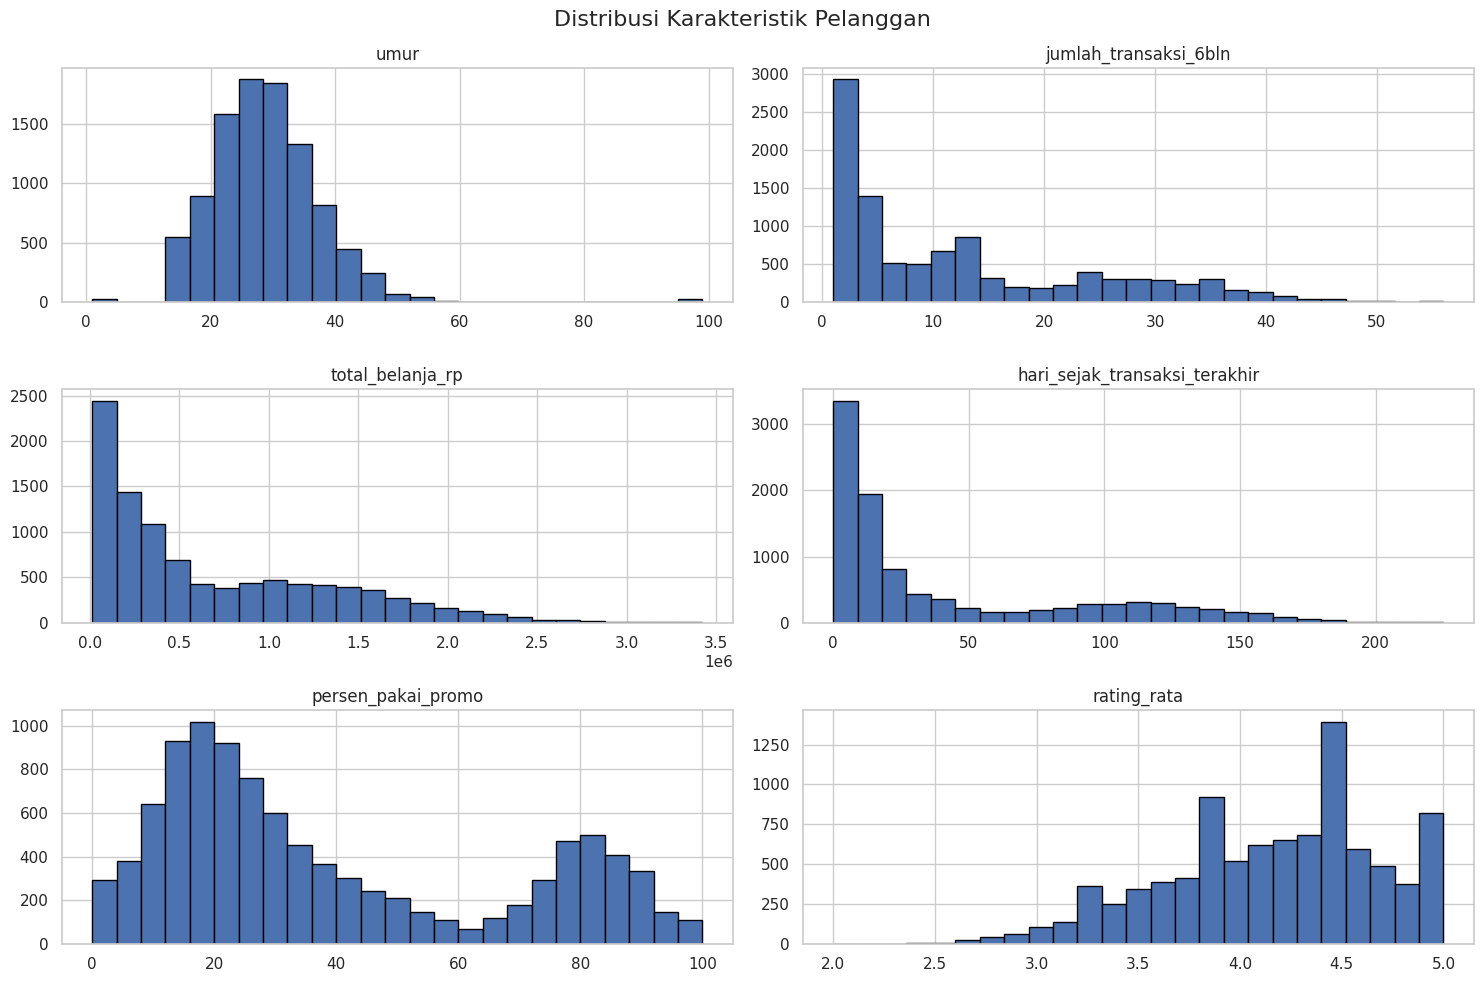

In [4]:
kolom_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

df[kolom_numerik].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribusi Karakteristik Pelanggan",
    fontsize=16
)

plt.tight_layout()
plt.show()

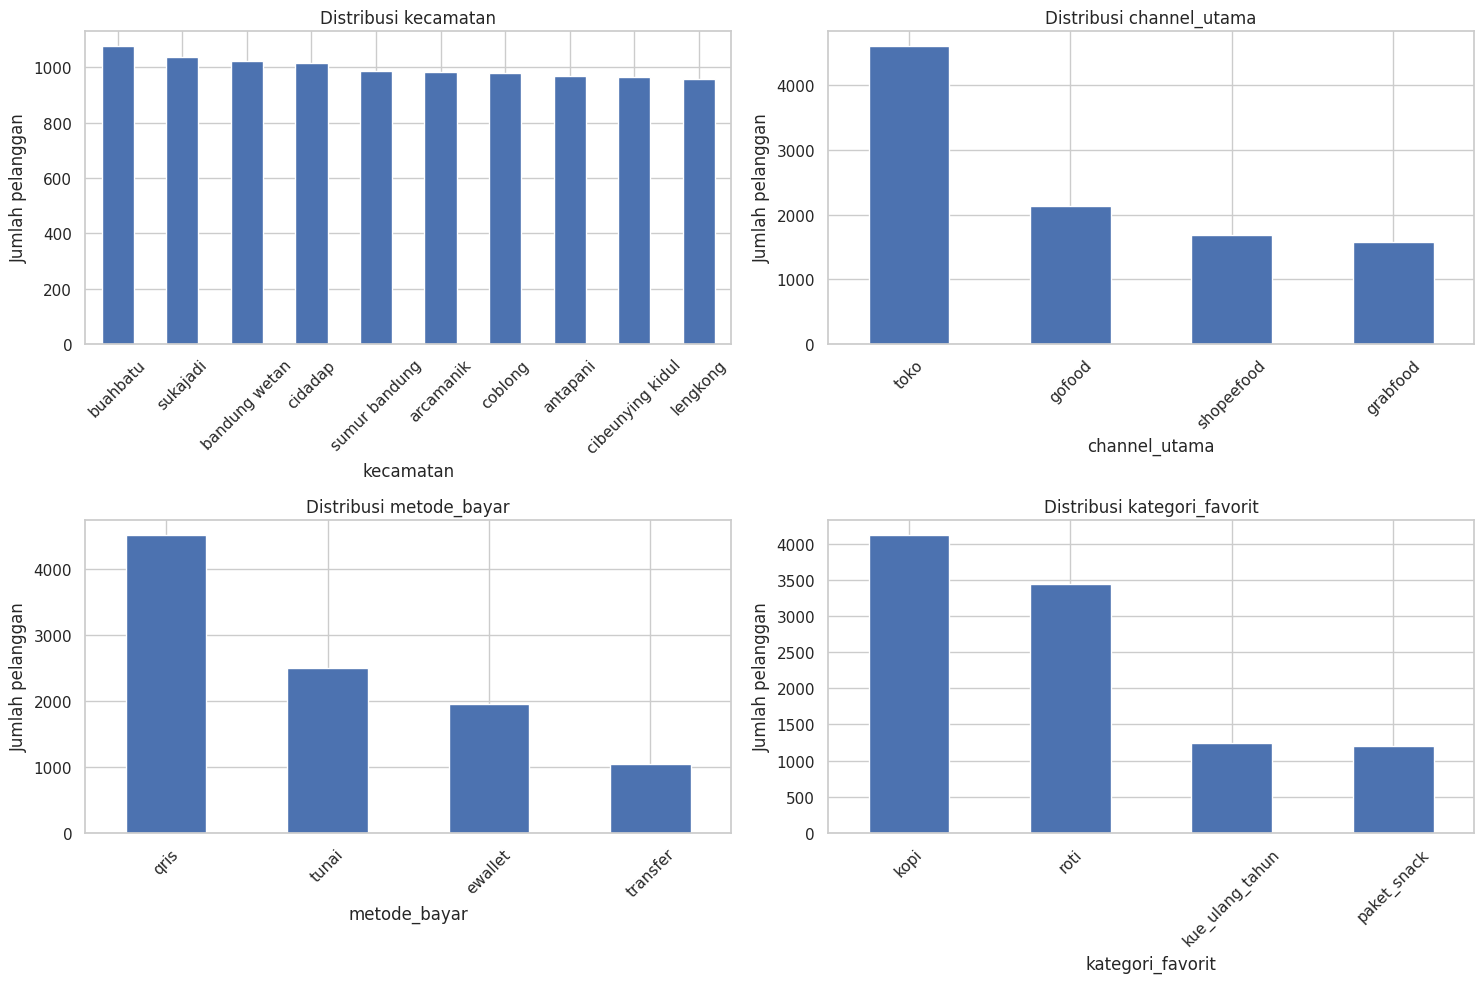

In [5]:
kolom_kategori = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, ax in zip(kolom_kategori, axes.flatten()):

    df[col].value_counts().plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Jumlah pelanggan")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

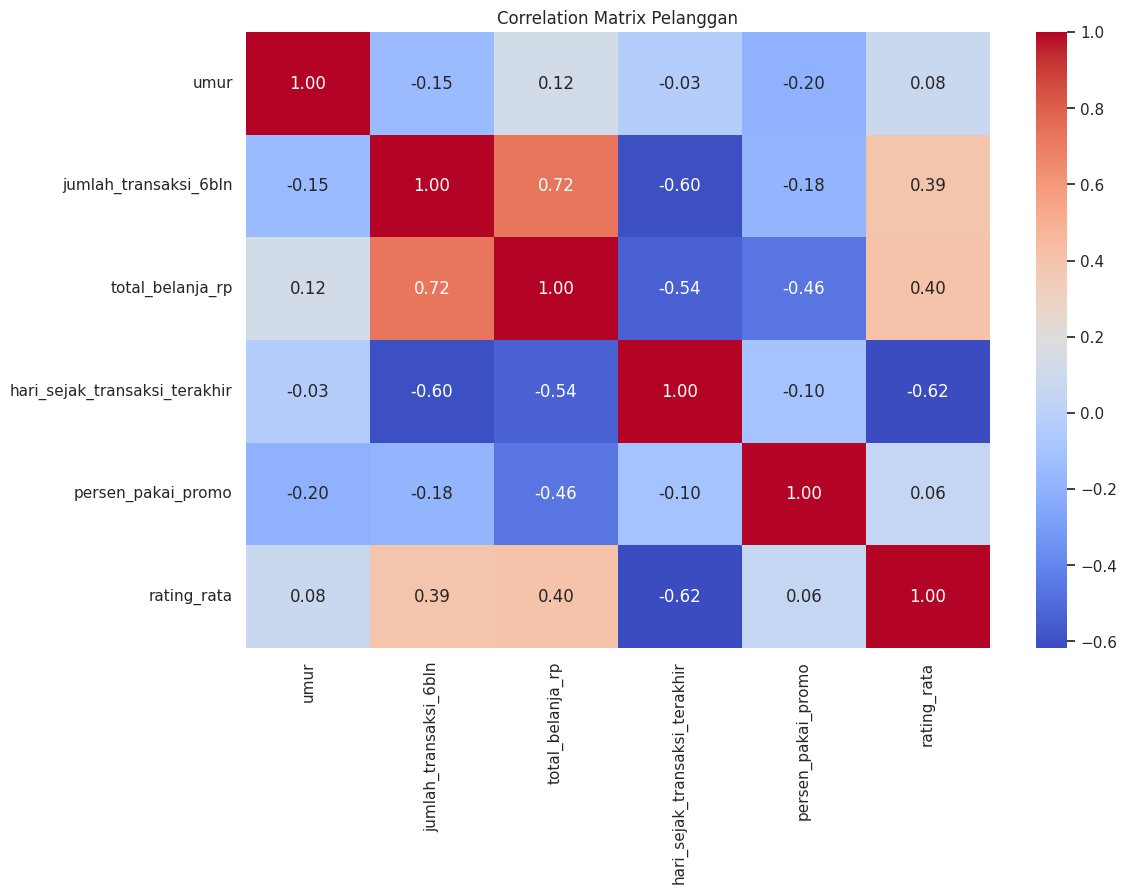

In [6]:
plt.figure(figsize=(12, 8))

corr = df[kolom_numerik].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix Pelanggan")
plt.show()

In [7]:
rfm = df[[
    "id_pelanggan",
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp"
]].copy()

rfm.columns = [
    "id_pelanggan",
    "Recency",
    "Frequency",
    "Monetary"
]

display(rfm.describe().T)

,count,mean,std,min,25%,50%,75%,max
Recency,10000.0,41.760,49.352274,0.0,6.0,15.0,75.0,225.0
Frequency,10000.0,12.535,11.643029,1.0,3.0,8.0,20.0,56.0
Monetary,10000.0,693710.740,648750.915942,11900.0,152200.0,425050.0,1145325.0,3424200.0


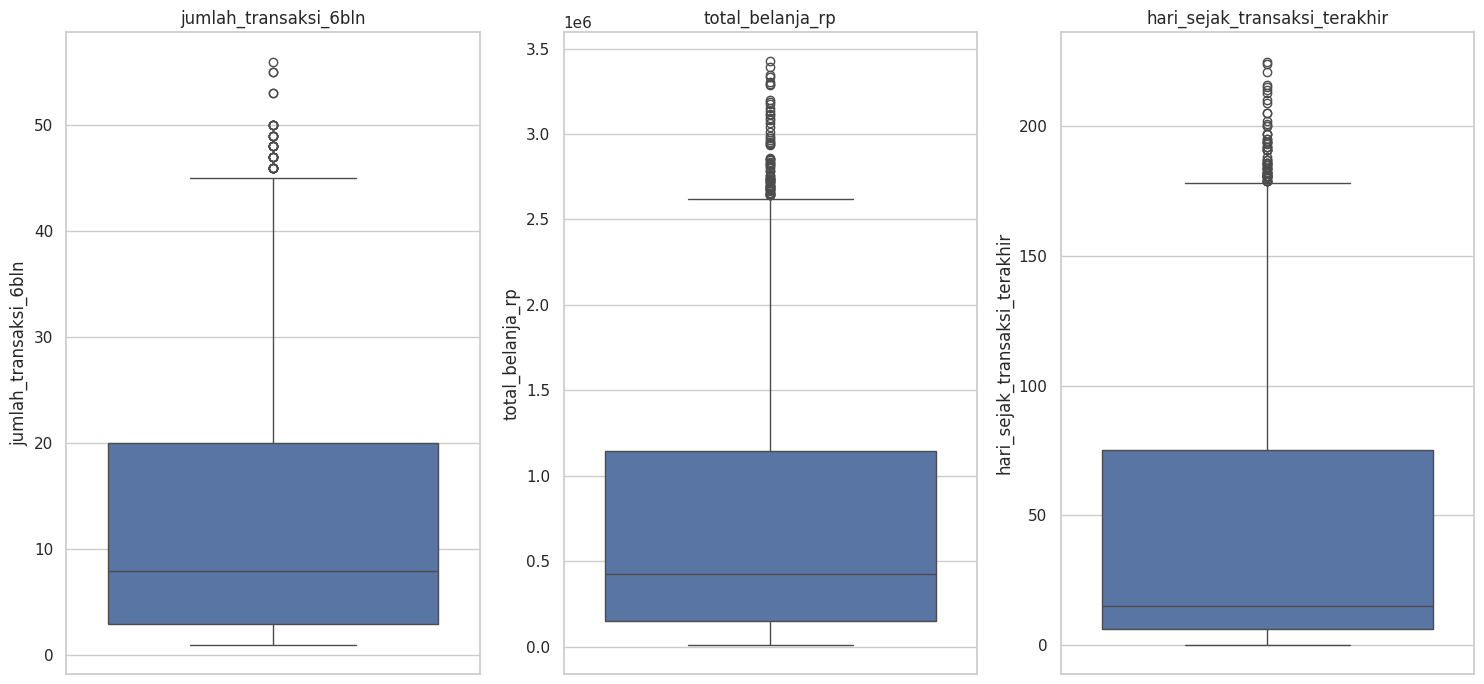

In [8]:
plt.figure(figsize=(15, 7))

for i, col in enumerate([
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir"
], 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()